# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

Collaborators: Narne Abhinav Chowdhary, Amanda Rae Josephine

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

Answers:   
c) 
This is because the rank formula equals the probability that a randomly selected positive example recieves a higher score than a randomly selected negative examples, where the equal scores contribute one half.

In [3]:
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    tp = np.sum((y_true == 1) & (y_pred == 1)) # positive class is 1 
    fn = np.sum((y_true == 1) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))

    return int(tp), int(fn), int(fp), int(tn)

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)

    n = tp + fn + fp + tn

    accuracy = (tp + tn) / n if n > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

def roc_curve(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)

    if len(y_true) != len(scores):
        raise ValueError("y_true and scores must have the same length")

    positives = np.sum(y_true == 1)
    negatives = np.sum(y_true == 0)

    if positives == 0 or negatives == 0:
        raise ValueError("ROC requires at least one positive and one negative")

    # Sort scores from largest to smallest
    order = np.argsort(-scores, kind="stable")
    sorted_scores = scores[order]
    sorted_labels = y_true[order]

    # Find the last index of every distinct score
    distinct = np.r_[np.where(np.diff(sorted_scores) != 0)[0], len(sorted_scores) - 1]

    cumulative_tp = np.cumsum(sorted_labels == 1)
    cumulative_fp = np.cumsum(sorted_labels == 0)

    tp = cumulative_tp[distinct]
    fp = cumulative_fp[distinct]

    tpr = tp / positives
    fpr = fp / negatives
    thresholds = sorted_scores[distinct]

    # Add the point where every sample is classified as negative
    fpr = np.r_[0.0, fpr]
    tpr = np.r_[0.0, tpr]
    thresholds = np.r_[np.inf, thresholds]

    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    fpr = np.asarray(fpr, dtype=float)
    tpr = np.asarray(tpr, dtype=float)

    if fpr.shape != tpr.shape:
        raise ValueError("fpr and tpr must have the same shape")

    # Trapezoid:
    # area = sum of width * average height
    return float(
        np.sum(
            0.5 * (tpr[1:] + tpr[:-1]) * np.diff(fpr)
        )
    )


def roc_auc(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)

    positives = y_true == 1
    negatives = y_true == 0

    n_positive = np.sum(positives)
    n_negative = np.sum(negatives)

    if n_positive == 0 or n_negative == 0:
        raise ValueError("AUC requires at least one positive and one negative")

    # Obtain average ranks for tied scores.
    # np.unique sorts the values in ascending order.
    unique_scores, inverse, counts = np.unique(
        scores,
        return_inverse=True,
        return_counts=True
    )

    # Rank of the first item in each tied group, using one-based ranks
    first_rank = np.cumsum(np.r_[1, counts[:-1]])

    # Average rank for each unique score
    average_rank = first_rank + (counts - 1) / 2

    ranks = average_rank[inverse]

    positive_rank_sum = np.sum(ranks[positives])

    auc = (
        positive_rank_sum
        - n_positive * (n_positive + 1) / 2
    ) / (n_positive * n_negative)

    return float(auc)


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


In [4]:
tp, fn, fp, tn = confusion_matrix(y_small, s_small > 0.5)

print("Own counts:")
print("TP:", tp, "FN:", fn, "FP:", fp, "TN:", tn)

print("\nScikit-learn matrix:")
print(skm.confusion_matrix(y_small, s_small > 0.5))

print("\nOwn report:")
print(classification_report(y_small, s_small > 0.5))

print("\nScikit-learn report:")
print({
    "accuracy": skm.accuracy_score(y_small, s_small > 0.5),
    "precision": skm.precision_score(y_small, s_small > 0.5, zero_division=0),
    "recall": skm.recall_score(y_small, s_small > 0.5, zero_division=0),
    "f1": skm.f1_score(y_small, s_small > 0.5, zero_division=0)
})

fpr, tpr, thresholds = roc_curve(y_small, s_small)

print("\nAUC using trapezoids:", auc_trapezoid(fpr, tpr))
print("AUC using rank formula:", roc_auc(y_small, s_small))
print("Scikit-learn AUC:", skm.roc_auc_score(y_small, s_small))

Own counts:
TP: 5 FN: 1 FP: 1 TN: 13

Scikit-learn matrix:
[[13  1]
 [ 1  5]]

Own report:
{'accuracy': 0.9, 'precision': 0.8333333333333334, 'recall': 0.8333333333333334, 'f1': 0.8333333333333334}

Scikit-learn report:
{'accuracy': 0.9, 'precision': 0.8333333333333334, 'recall': 0.8333333333333334, 'f1': 0.8333333333333334}

AUC using trapezoids: 0.8571428571428572
AUC using rank formula: 0.8571428571428571
Scikit-learn AUC: 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


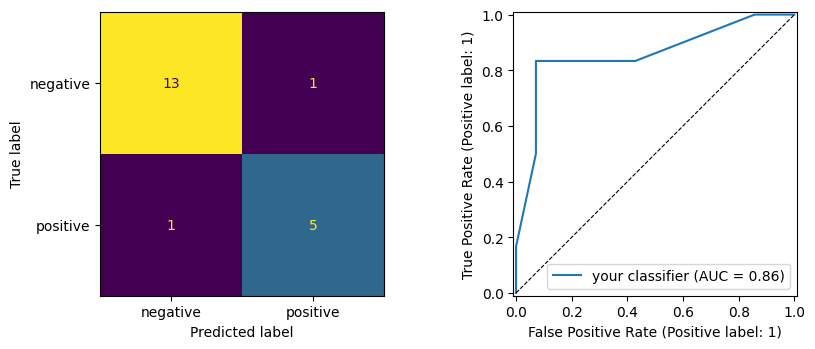

In [6]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

Answers:  
b)
The confusion matrix shows the seperate numbers of true positives, false positives, true negatives, and false negatives, whereas 2 classifiers can have similar accuracy while having very different recall or precision, especially when the positive class is much smaller than the negative class. 

c) 
The errors live in the region where the probability distributions of the 2 classes intersect. The confusion matrix describes performance at one threshold, while AUC measures ranking performance over all possible thresholds.Therefore, the 2 models can have similar confusion matrices at threshold 0.5 but different AUC values. 

d) 
The standard error of accuracy uses the whole test set while the standard error of recall only uses the number of true positive class examples. If the accuracy intervals overlap substantially, the observed difference should not simply be considered statistically significant. 

In [7]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix as sk_confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load MNIST
data = np.load("mnist.npz")

d = 3                                # your digit
data = np.load("mnist.npz")            # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
x_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_train = (data["y_train"] == d).astype(float)
y_test = (data["y_test"] == d).astype(float)

print("Training set:", x_train.shape)
print("Test set:", x_test.shape)
print("Selected digit:", d)

Training set: (60000, 784)
Test set: (10000, 784)
Selected digit: 3


In [8]:
# part a
prevalence = np.mean(y_test == 1)
majority_predictions = np.zeros_like(y_test)

majority_accuracy = accuracy_score(y_test, majority_predictions)
majority_error = 1.0 - majority_accuracy

print(f"Prevalence of digit {d}: {prevalence:.4f}")
print(f"Majority-rule accuracy: {majority_accuracy:.4f}")
print(f"Majority-rule error: {majority_error:.4f}")

Prevalence of digit 3: 0.1010
Majority-rule accuracy: 0.8990
Majority-rule error: 0.1010


In [14]:
# part b

# Logistic regression: no hidden layer
logistic_model = LogisticRegression(
    max_iter=100,
    solver="lbfgs",
    random_state=2026
)

logistic_model.fit(x_train, y_train)

p_logistic = logistic_model.predict_proba(x_test)[:, 1]
pred_logistic = (p_logistic >= 0.5).astype(int)


# Neural network with one hidden layer
hidden_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="logistic",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=128,
    max_iter=100,
    tol=1e-3,
    random_state=2026,
    verbose=False
)

hidden_model.fit(x_train, y_train)

p_hidden = hidden_model.predict_proba(x_test)[:, 1]
pred_hidden = (p_hidden >= 0.5).astype(int)

print("Iterations used:", hidden_model.n_iter_)
print("Final loss:", hidden_model.loss_)

Iterations used: 19
Final loss: 0.07660206451486874


In [15]:
# report both models 

def report_model(name, y_true, probabilities, predictions, majority_error):
    tp, fn, fp, tn = confusion_matrix(y_true, predictions)
    report = classification_report(y_true, predictions)

    error = 1.0 - report["accuracy"]
    error_removed = (
        (majority_error - error) / majority_error
        if majority_error > 0 else 0.0
    )

    print(f"\n{name}")
    print("-" * len(name))
    print("Confusion matrix in [[TN, FP], [FN, TP]] layout:")
    print(np.array([[tn, fp], [fn, tp]]))

    print(f"TP={tp}, FN={fn}, FP={fp}, TN={tn}")
    print(f"Accuracy:  {report['accuracy']:.4f}")
    print(f"Precision: {report['precision']:.4f}")
    print(f"Recall:    {report['recall']:.4f}")
    print(f"F1 score:  {report['f1']:.4f}")
    print(f"Error removed relative to majority rule: {error_removed:.2%}")

    print("\nScikit-learn check:")
    print(sk_confusion_matrix(y_true, predictions))
    print(f"Accuracy:  {accuracy_score(y_true, predictions):.4f}")
    print(f"Precision: {precision_score(y_true, predictions, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, predictions, zero_division=0):.4f}")
    print(f"F1 score:  {f1_score(y_true, predictions, zero_division=0):.4f}")


report_model(
    "Logistic regression",
    y_test,
    p_logistic,
    pred_logistic,
    majority_error
)

report_model(
    "One-hidden-layer network",
    y_test,
    p_hidden,
    pred_hidden,
    majority_error
)


Logistic regression
-------------------
Confusion matrix in [[TN, FP], [FN, TP]] layout:
[[8907   83]
 [ 141  869]]
TP=869, FN=141, FP=83, TN=8907
Accuracy:  0.9776
Precision: 0.9128
Recall:    0.8604
F1 score:  0.8858
Error removed relative to majority rule: 77.82%

Scikit-learn check:
[[8907   83]
 [ 141  869]]
Accuracy:  0.9776
Precision: 0.9128
Recall:    0.8604
F1 score:  0.8858

One-hidden-layer network
------------------------
Confusion matrix in [[TN, FP], [FN, TP]] layout:
[[8926   64]
 [ 143  867]]
TP=867, FN=143, FP=64, TN=8926
Accuracy:  0.9793
Precision: 0.9313
Recall:    0.8584
F1 score:  0.8934
Error removed relative to majority rule: 79.50%

Scikit-learn check:
[[8926   64]
 [ 143  867]]
Accuracy:  0.9793
Precision: 0.9313
Recall:    0.8584
F1 score:  0.8934


Logistic regression AUC:
  Trapezoidal: 0.9853131642418969
  Rank: 0.985313164241897
  sklearn: 0.9853131642418969

One-hidden-layer network AUC:
  Trapezoidal: 0.986635866033767
  Rank: 0.9866358660337669
  sklearn: 0.986635866033767


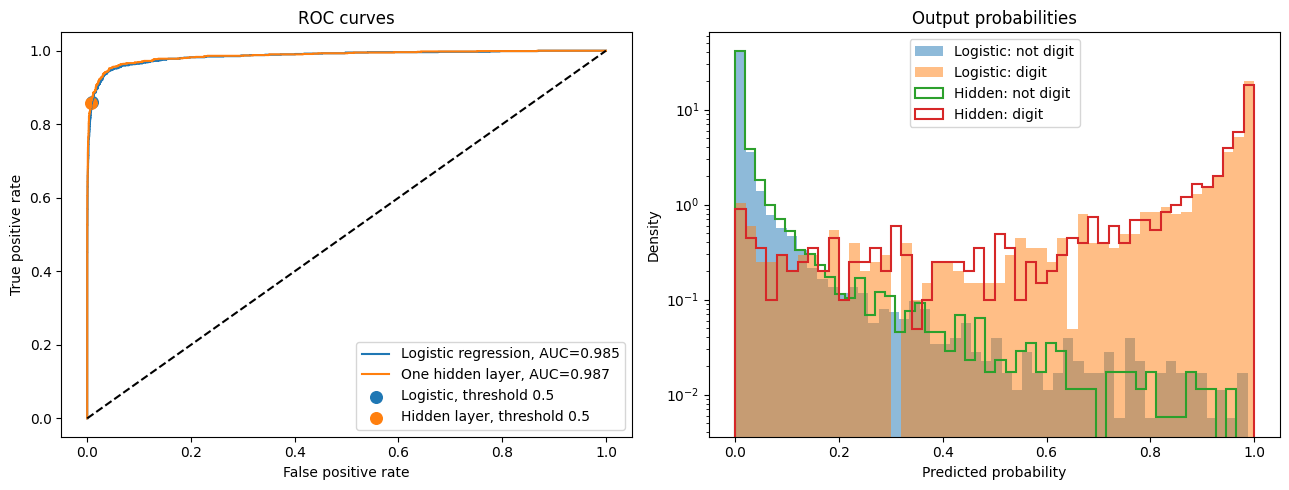

In [16]:
# part c 
fpr_log, tpr_log, thresholds_log = roc_curve(y_test, p_logistic)
fpr_hidden, tpr_hidden, thresholds_hidden = roc_curve(y_test, p_hidden)

print("Logistic regression AUC:")
print("  Trapezoidal:", auc_trapezoid(fpr_log, tpr_log))
print("  Rank:", roc_auc(y_test, p_logistic))
print("  sklearn:", roc_auc_score(y_test, p_logistic))

print("\nOne-hidden-layer network AUC:")
print("  Trapezoidal:", auc_trapezoid(fpr_hidden, tpr_hidden))
print("  Rank:", roc_auc(y_test, p_hidden))
print("  sklearn:", roc_auc_score(y_test, p_hidden))

def threshold_point(y_true, probabilities, threshold=0.5):
    predictions = probabilities >= threshold
    tp, fn, fp, tn = confusion_matrix(y_true, predictions)

    tpr = tp / (tp + fn) if tp + fn > 0 else 0.0
    fpr = fp / (fp + tn) if fp + tn > 0 else 0.0

    return fpr, tpr


point_log = threshold_point(y_test, p_logistic, 0.5)
point_hidden = threshold_point(y_test, p_hidden, 0.5)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# ROC plot
ax[0].plot(
    fpr_log,
    tpr_log,
    label=f"Logistic regression, AUC={roc_auc(y_test, p_logistic):.3f}"
)

ax[0].plot(
    fpr_hidden,
    tpr_hidden,
    label=f"One hidden layer, AUC={roc_auc(y_test, p_hidden):.3f}"
)

ax[0].scatter(
    point_log[0],
    point_log[1],
    s=70,
    label="Logistic, threshold 0.5"
)

ax[0].scatter(
    point_hidden[0],
    point_hidden[1],
    s=70,
    label="Hidden layer, threshold 0.5"
)

ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves")
ax[0].legend()

# Probability histograms
ax[1].hist(
    p_logistic[y_test == 0],
    bins=50,
    alpha=0.5,
    density=True,
    label="Logistic: not digit"
)

ax[1].hist(
    p_logistic[y_test == 1],
    bins=50,
    alpha=0.5,
    density=True,
    label="Logistic: digit"
)

ax[1].hist(
    p_hidden[y_test == 0],
    bins=50,
    histtype="step",
    linewidth=1.5,
    density=True,
    label="Hidden: not digit"
)

ax[1].hist(
    p_hidden[y_test == 1],
    bins=50,
    histtype="step",
    linewidth=1.5,
    density=True,
    label="Hidden: digit"
)

ax[1].set_yscale("log")
ax[1].set_xlabel("Predicted probability")
ax[1].set_ylabel("Density")
ax[1].set_title("Output probabilities")
ax[1].legend()

plt.tight_layout()
plt.show()

In [18]:
# part d

def proportion_standard_error(p, n):
    return np.sqrt(p * (1.0 - p) / n)


def model_standard_errors(y_true, predictions):
    tp, fn, fp, tn = confusion_matrix(y_true, predictions)

    n_total = len(y_true)
    accuracy = (tp + tn) / n_total
    accuracy_se = proportion_standard_error(accuracy, n_total)

    n_positive = tp + fn
    recall = tp / n_positive if n_positive > 0 else 0.0
    recall_se = (proportion_standard_error(recall, n_positive) if n_positive > 0 else 0.0)

    return accuracy, accuracy_se, recall, recall_se


for name, predictions in [ ("Logistic regression", pred_logistic), ("One-hidden-layer network", pred_hidden)]:
    accuracy, accuracy_se, recall, recall_se = model_standard_errors( y_test, predictions)

    print(name)
    print(f"Accuracy: {accuracy:.4f} ± {accuracy_se:.4f}")
    print(f"Recall:   {recall:.4f} ± {recall_se:.4f}")
    print()

Logistic regression
Accuracy: 0.9776 ± 0.0015
Recall:   0.8604 ± 0.0109

One-hidden-layer network
Accuracy: 0.9793 ± 0.0014
Recall:   0.8584 ± 0.0110



## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …